# Part G — Haslam calibrated with one gain and offset

**Origin:** `notebooks/17_haslam_gain_offset_calibration.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/17_haslam_gain_offset_calibration.ipynb`)

| | |
|---|---|
| **Reads** | `paper_outputs/pipeline/step5_fit/` (`fits/`, `ring_ra.npy`), `paper_outputs/pipeline/step2_ring_tods/``sky_tods.npz`, `configs/model_comp_config.yaml` |
| **Writes** | `test_outputs/plot3_haslam_calibration/` |
| **Feeds the paper** | possibly the "2–3 K after the best single gain and offset" in main.tex:647 (not confirmed); its g, z equal fig9 (c) |

**Stored outputs** are from the original notebook (not re-run after the merge).

**Pipeline:** reads the pipeline's step 2 and step 5 products.

**Data sets:** step 5's data sets (`moonrunes.pipeline.fit_data_sets`: every map `sed.exclude_maps` leaves in with data on the ring, plus TRIS 600 and 820; 13 points with the current config). Where the text below names the six ring surveys, read these. The stored outputs are from the six-point set.

## Calibrating Haslam 408 MHz with a gain and an offset

**Purpose.** This is Phil's plot 3: Haslam 408 MHz calibrated with a **gain and an offset** along the TRIS
ring, against the power law fitted at each ring sample to every survey that has a ring TOD.

**The fit.** At each ring sample $i$ the sky is a power law $A_i\,(\nu/408\ \mathrm{MHz})^{\beta_i}$. It
is fitted to all the feasible ring surveys: TRIS 600 and 820 MHz (effective 600.5 and 817.8 MHz,
`ring_sigma` errors), LWA1 35 and 80 MHz, Maipu 45 MHz and Stockert 1420 MHz (published errors). These
are the six surveys with ring TODs on the TOD route, as in notebooks 12–16. CHIPASS and Rhodes cover
only part of the sky and enter only the map route, and ARCADE 2 is excluded (`sed.exclude_maps`).
Haslam is not one of the fit points: it is the map being calibrated, with a gain $g$ and offset $z$
shared by all samples:

$$T_{\mathrm{Haslam},i} = g\,A_i + z.$$

A sample is fitted only if it has at least **4** usable points (`min_points` in
`configs/model_comp_config.yaml`), so the power law has at least 2 degrees of freedom. Every ring sample
has all six.

The fit is done in two steps:

1. Per sample, the power-law fit to the six surveys gives the predicted 408 MHz value $P_i = A_i$. This
   is the maximum-likelihood point of notebook 12's UltraNest fit, with the posterior standard deviation
   of $A_i$ as its error.
2. A York errors-in-variables fit of Haslam$_i$ (y) against $P_i$ (x) gives $g$, $z$ and their errors
   and covariance. σ is inflated by √(χ²/ν) when χ²/ν > 1, as in notebook 14.

This is **equivalent to the joint fit** of $g$, $z$ and all $(A_i, \beta_i)$, with Haslam as a seventh
point $g A_i + z$ at each sample. The equivalence holds to first order, treating the posterior of $A_i$
(with $\beta_i$ marginalised) as Gaussian: York's adjusted $x_i$ is the joint fit's $A_i$. The fit is
the same as notebook 16's uncorrected-Haslam row ($a = g$, $b = z$), written here as a correction.

The result is reported as the **correction to Haslam**,

$$T_\mathrm{corrected} = s\,T_\mathrm{Haslam} + o, \qquad s = 1/g, \qquad o = -z/g,$$

with propagated errors. Uncorrected Haslam is $(s, o) = (1, 0)$. It is compared with the published
corrections in `sky_tods.npz` (Carter, Irfan and GINAN), each reduced to its own $(s_k, o_k)$.

* **Figure 1:** Haslam against the power-law prediction, T–T.
* **Figure 2 (main result):** the calibration plane (s, o).
* **Figure 3:** the prediction and the Haslam versions along the ring, with residuals.
* **Table:** the fit (all samples and without Cygnus A) and the published corrections.

All temperatures are Rayleigh–Jeans with the CMB removed, through the TRIS beam.

> **Caveats.**
> * **Correlated samples.** The 120 ring samples are 3° apart under a ~20° beam, so they are correlated.
>   Every σ here is an underestimate, by roughly √(120/18) ≈ ×2.6.
> * **The prediction.** The power law's 408 MHz value is an interpolation between LWA1 80 and TRIS 600,
>   so it is only as good as that fit. TRIS 600 (σ/T ≈ 0.5%) carries most of the weight, so P's error is
>   small (≈ 0.5%).
> * **Common errors.** The scale and zero-level errors (Haslam 10% ⊕ 3 K, the surveys' published scale and
>   zero levels, the TRIS zero levels) are common to all samples, but they are treated here as
>   independent per sample.
> * **A single power law from 35 MHz to 1.4 GHz is assumed.** Curvature is not tested here.
> * **No causes.** The text describes sizes and positions only.

**Inputs** (read only), from notebook 12's cache `paper_outputs/sky_models_408/cache/`:
`fits/unitNNN__power_law.npz` (the power-law fit per ring sample, with its data points), `sky_tods.npz`
(Haslam and its published corrections at 408 MHz through the TRIS beam, with beam coverage) and
`ring_ra.npy`. Loading code, style and caveats follow notebook 16, and `york` is copied from
notebook 14. Figures and the CSV go to `test_outputs/plot3_haslam_calibration/`.
Rerun: Restart & Run All (seconds).

In [ ]:
%matplotlib inline
import time as _nb_time; _NB_T0 = _nb_time.time()   # notebook run time, printed by the last cell
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Patch

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "run_pipeline.yaml").exists())
PIPE2 = REPO / "paper_outputs" / "pipeline" / "step2_ring_tods"   # run_pipeline.py step 2 (ring TODs), read only
PIPE5 = REPO / "paper_outputs" / "pipeline" / "step5_fit"         # run_pipeline.py step 5 (our model's fits), read only
OUT_DIR = REPO / "test_outputs" / "plot3_haslam_calibration"
HASLAM_FILE = "HASLAM_DESTRIPED_ONLY.fits"

COV_MIN = 0.5              # a model sample is kept when its beam coverage >= this (notebooks 12-16)
INFLATE = True             # scale σ by sqrt(χ²/ν) when χ²/ν > 1 (notebook 14's rule)
CYG_A_RA, CYG_HALF = 299.9, 25.0     # Cygnus A and the half-width of the excluded / shaded window [deg]
with open(REPO / "configs" / "model_comp_config.yaml") as f:
    MIN_POINTS = int(yaml.safe_load(f)["data"]["min_points"])   # 4: minimum usable points per power-law fit
# The surveys with ring TODs on the TOD route (the fit points of notebooks 12-16); Haslam is not one of them.
# RING_SURVEYS: step 5's data sets, set where the fits are read (moonrunes.pipeline.fit_data_sets)
NU_H = 408.0

# sky_tods.npz order: 0 Haslam, 1 Carter, 2 Irfan, 3 GSM2008, 4 GSM2016, 5 GINAN, 6 LFSM
HASLAM = "Haslam (uncorrected)"
CORRECTIONS = {"Haslam, Carter correction": "Carter", "Haslam, Irfan correction": "Irfan",
               "GSM2016, GINAN correction": "GINAN"}
# Okabe-Ito, as notebooks 13 and 16
COLOUR = {"P": "black", "Haslam": "#E69F00", "fit": "#009E73", "Carter": "#56B4E9", "Irfan": "#CC79A7",
          "GINAN": "#882255"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 24, "axes.titlesize": 24,
                     "axes.labelsize": 24, "legend.fontsize": 22, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Save a figure as PNG in OUT_DIR, then show it inline.
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

### 1. Inputs

* **The power-law prediction P:** at each ring sample, the maximum-likelihood `A_K` of the cached
  power-law fit, and the standard deviation of its posterior `A_K` samples (notebook 16's x axis). The
  cell checks which surveys each fit used and how many points it had. A sample is used only if its fit
  had at least `MIN_POINTS` (4) points, all from the six ring surveys.
* **Haslam and the corrections:** the 408 MHz ring TODs from `sky_tods.npz`, kept where the beam coverage
  is ≥ `COV_MIN`. Haslam's error is `sed_prototype.sigma_for` (10% scale ⊕ 3 K zero level), as in
  notebooks 14 and 16.

A sample is used when Haslam's coverage is ≥ 0.5 and its power-law fit is valid.

In [ ]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO / "src"))
from moonrunes.sed_prototype import sigma_for
from moonrunes.pipeline import fit_data_sets
RING_SURVEYS = fit_data_sets()         # step 5's data sets (TRIS included): key -> label

RA = np.load(PIPE5 / "ring_ra.npy")
N = RA.size

z = np.load(PIPE2 / "sky_tods.npz", allow_pickle=False)
names = [str(n) for n in z["names"]]
assert names[0] == HASLAM and set(CORRECTIONS) <= set(names), names
T_MOD = {n: np.where(z[f"cov_{i}"] >= COV_MIN, z[f"tod_{i}"], np.nan) for i, n in enumerate(names)}
T_H = T_MOD[HASLAM]
S_H = np.asarray(sigma_for(dict(freq_mhz=NU_H, file=HASLAM_FILE), T_H), dtype=float)

P, S_P, NPTS = np.full(N, np.nan), np.full(N, np.nan), np.zeros(N, dtype=int)
used = {k: 0 for k in RING_SURVEYS}
for u in range(N):
    p = PIPE5 / "fits" / f"unit{u:03d}__power_law.npz"
    if not p.exists():
        continue
    r = np.load(p, allow_pickle=False)
    keys = [str(x) for x in r["keys"]]
    assert set(keys) <= set(RING_SURVEYS) and HASLAM_FILE not in keys, keys   # Haslam is never a fit point
    NPTS[u] = len(keys)
    for k in keys:
        used[k] += 1
    if NPTS[u] < MIN_POINTS:
        continue
    iA = [str(x) for x in r["names"]].index("A_K")
    P[u] = float(r["maxpoint"][iA])
    S_P[u] = float(np.std(r["samples"][:, iA]))

USE = np.isfinite(P) & np.isfinite(S_P) & np.isfinite(T_H) & np.isfinite(S_H)
CYG = np.abs(RA - CYG_A_RA) <= CYG_HALF
print("power-law fit points per sample:", {int(k): int(v) for k, v in zip(*np.unique(NPTS, return_counts=True))},
      f"(minimum required {MIN_POINTS})")
print("samples using each survey:", {RING_SURVEYS[k]: v for k, v in used.items()})
print(f"{int(USE.sum())} of {N} samples used (Haslam coverage ≥ {COV_MIN}, power-law fit with ≥ {MIN_POINTS} points); "
      f"{int((USE & CYG).sum())} in RA {CYG_A_RA - CYG_HALF:g}–{CYG_A_RA + CYG_HALF:g}°")
print(f"P(408): median {np.nanmedian(P[USE]):.2f} K, median σ_P/P {100 * np.nanmedian(S_P[USE] / P[USE]):.2f}%;  "
      f"Haslam median σ/T {100 * np.nanmedian(S_H[USE] / T_H[USE]):.1f}%")

power-law fit points per sample: {6: 120} (minimum required 4)
samples using each survey: {'TRIS 600': 120, 'TRIS 820': 120, 'LWA1 35': 120, 'Maipu 45': 120, 'LWA1 80': 120, 'Stockert 1420': 120}
120 of 120 samples used (Haslam coverage ≥ 0.5, power-law fit with ≥ 4 points); 17 in RA 274.9–324.9°
P(408): median 32.13 K, median σ_P/P 0.54%;  Haslam median σ/T 14.4%


### 2. The gain–offset fit and the correction to Haslam

`york` is copied unchanged from notebook 14 (the same function as notebook 16). It does not return the
covariance of slope and intercept, so `york_cov` computes it alongside, from York et al. (2004) for the
same data and slope: cov(a, b) = −x̄_adj σ_a², where x̄_adj is the weighted mean of the adjusted x values.
It applies the same √(χ²/ν) inflation. This covariance is used for the errors on (s, o) and for the
ellipses in Figure 2. Then

$$s = 1/g, \qquad o = -z/g, \qquad
J = \begin{pmatrix} -1/g^2 & 0 \\ z/g^2 & -1/g \end{pmatrix}, \qquad C_{so} = J\,C_{gz}\,J^\mathsf{T}.$$

The fit is run with all samples and with RA 299.9 ± 25° excluded.

In [ ]:
def york(x, y, sx, sy, n_iter=200, tol=1e-12):
    # y = a x + b with errors on both axes (York et al. 2004, Am. J. Phys. 72, 367; no x-y correlation).
    vx, vy = np.asarray(sx, float) ** 2, np.asarray(sy, float) ** 2
    a = np.polyfit(x, y, 1)[0]
    for _ in range(n_iter):
        W = 1.0 / (vy + a * a * vx)
        xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
        U, V = x - xb, y - yb
        bet = W * (U * vy + a * V * vx)
        a_new = np.sum(W * bet * V) / np.sum(W * bet * U)
        done = abs(a_new - a) <= tol * abs(a_new)
        a = a_new
        if done:
            break
    W = 1.0 / (vy + a * a * vx)
    xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
    b = yb - a * xb
    xa = xb + W * ((x - xb) * vy + a * (y - yb) * vx)          # adjusted x values
    xab = np.sum(W * xa) / W.sum()
    sa = np.sqrt(1.0 / np.sum(W * (xa - xab) ** 2))
    sb = np.sqrt(1.0 / W.sum() + xab ** 2 * sa ** 2)
    chi2 = float(np.sum(W * (y - a * x - b) ** 2))
    dof = x.size - 2
    f = np.sqrt(max(1.0, chi2 / dof)) if INFLATE else 1.0
    return dict(a=a, sa=sa * f, b=b, sb=sb * f, chi2_dof=chi2 / dof)

def york_cov(x, y, sx, sy, fit):
    # cov(a, b) of the York fit above (York et al. 2004: -x̄_adj σ_a²), with the same √(χ²/ν) inflation.
    vx, vy, a = np.asarray(sx, float) ** 2, np.asarray(sy, float) ** 2, fit["a"]
    W = 1.0 / (vy + a * a * vx)
    xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
    xa = xb + W * ((x - xb) * vy + a * (y - yb) * vx)
    xab = np.sum(W * xa) / W.sum()
    return -xab * fit["sa"] ** 2

def calibrate(exclude_cyg=False):
    ok = USE & ~CYG if exclude_cyg else USE
    x, y, sx, sy = P[ok], T_H[ok], S_P[ok], S_H[ok]
    f = york(x, y, sx, sy)
    g, zz = f["a"], f["b"]
    cgz = york_cov(x, y, sx, sy, f)
    C = np.array([[f["sa"] ** 2, cgz], [cgz, f["sb"] ** 2]])
    J = np.array([[-1 / g ** 2, 0.0], [zz / g ** 2, -1 / g]])
    Cso = J @ C @ J.T
    return dict(g=g, sg=f["sa"], z=zz, sz=f["sb"], rho_gz=cgz / (f["sa"] * f["sb"]), chi2_dof=f["chi2_dof"],
                n=int(ok.sum()), s=1 / g, o=-zz / g, ss=np.sqrt(Cso[0, 0]), so=np.sqrt(Cso[1, 1]),
                rho_so=Cso[0, 1] / np.sqrt(Cso[0, 0] * Cso[1, 1]), C_so=Cso)

CAL = {ex: calibrate(ex) for ex in (False, True)}
MAIN = CAL[False]
for ex, c in CAL.items():
    print(f"{'excl. Cygnus' if ex else 'all':<12}: g = {c['g']:.3f} ± {c['sg']:.3f}, z = {c['z']:+.2f} ± {c['sz']:.2f} K "
          f"(ρ = {c['rho_gz']:+.2f}) -> s = {c['s']:.3f} ± {c['ss']:.3f}, o = {c['o']:+.2f} ± {c['so']:.2f} K "
          f"(ρ = {c['rho_so']:+.2f}); χ²/ν = {c['chi2_dof']:.3g}, N = {c['n']}")

all         : g = 1.017 ± 0.038, z = -3.85 ± 1.14 K (ρ = -0.95) -> s = 0.983 ± 0.037, o = +3.78 ± 0.98 K (ρ = -0.93); χ²/ν = 0.0645, N = 120
excl. Cygnus: g = 1.055 ± 0.054, z = -4.77 ± 1.47 K (ρ = -0.97) -> s = 0.948 ± 0.048, o = +4.52 ± 1.17 K (ρ = -0.95); χ²/ν = 0.0565, N = 103


### 3. The published corrections as (s, o)

Each correction's 408 MHz ring TOD is fitted against uncorrected Haslam's with an ordinary straight line,
$T_k = s_k\,T_\mathrm{Haslam} + o_k$, over the samples where both have coverage ≥ 0.5. The **scatter** is
the rms of the residuals. Carter (1.029 × Haslam + 0.91 K) and Irfan (an offset only) are linear in Haslam
and the beam is normalised, so their scatter should be at rounding level. GINAN is a correction to GSM2016
and is not linear in Haslam, so its (s, o) is only the best straight line.

In [ ]:
CORR = {}
for name, short in CORRECTIONS.items():
    y = T_MOD[name]
    ok = np.isfinite(T_H) & np.isfinite(y)
    sk, ok_ = np.polyfit(T_H[ok], y[ok], 1)
    CORR[short] = dict(s=sk, o=ok_, scatter=float(np.sqrt(np.mean((y[ok] - (sk * T_H[ok] + ok_)) ** 2))), n=int(ok.sum()))
    print(f"{short:<7}: s = {sk:.4f}, o = {ok_:+.3f} K, rms scatter {CORR[short]['scatter']:.3g} K (N = {CORR[short]['n']})")

Carter : s = 1.0290, o = +0.910 K, rms scatter 1.98e-13 K (N = 120)
Irfan  : s = 1.0000, o = -6.184 K, rms scatter 1.45e-13 K (N = 120)
GINAN  : s = 1.4383, o = -9.496 K, rms scatter 1.16 K (N = 120)


#### Figure 1 — Haslam against the power-law prediction

x is the power-law prediction at 408 MHz, P_i, from the fit to the six ring surveys, and y is the
uncorrected Haslam ring TOD. The points are the ring samples, coloured by RA, drawn without error bars
(the fit uses them: σ_P/P ≈ 0.5%, and Haslam's 10% ⊕ 3 K). The dashed line is 1:1 and the black line is
the York fit T_Haslam = g P + z; g, z, their errors and χ²/ν are in the table at the end. **σ are
underestimates**: correlated samples, and the common scale and zero-level errors are treated as
independent.

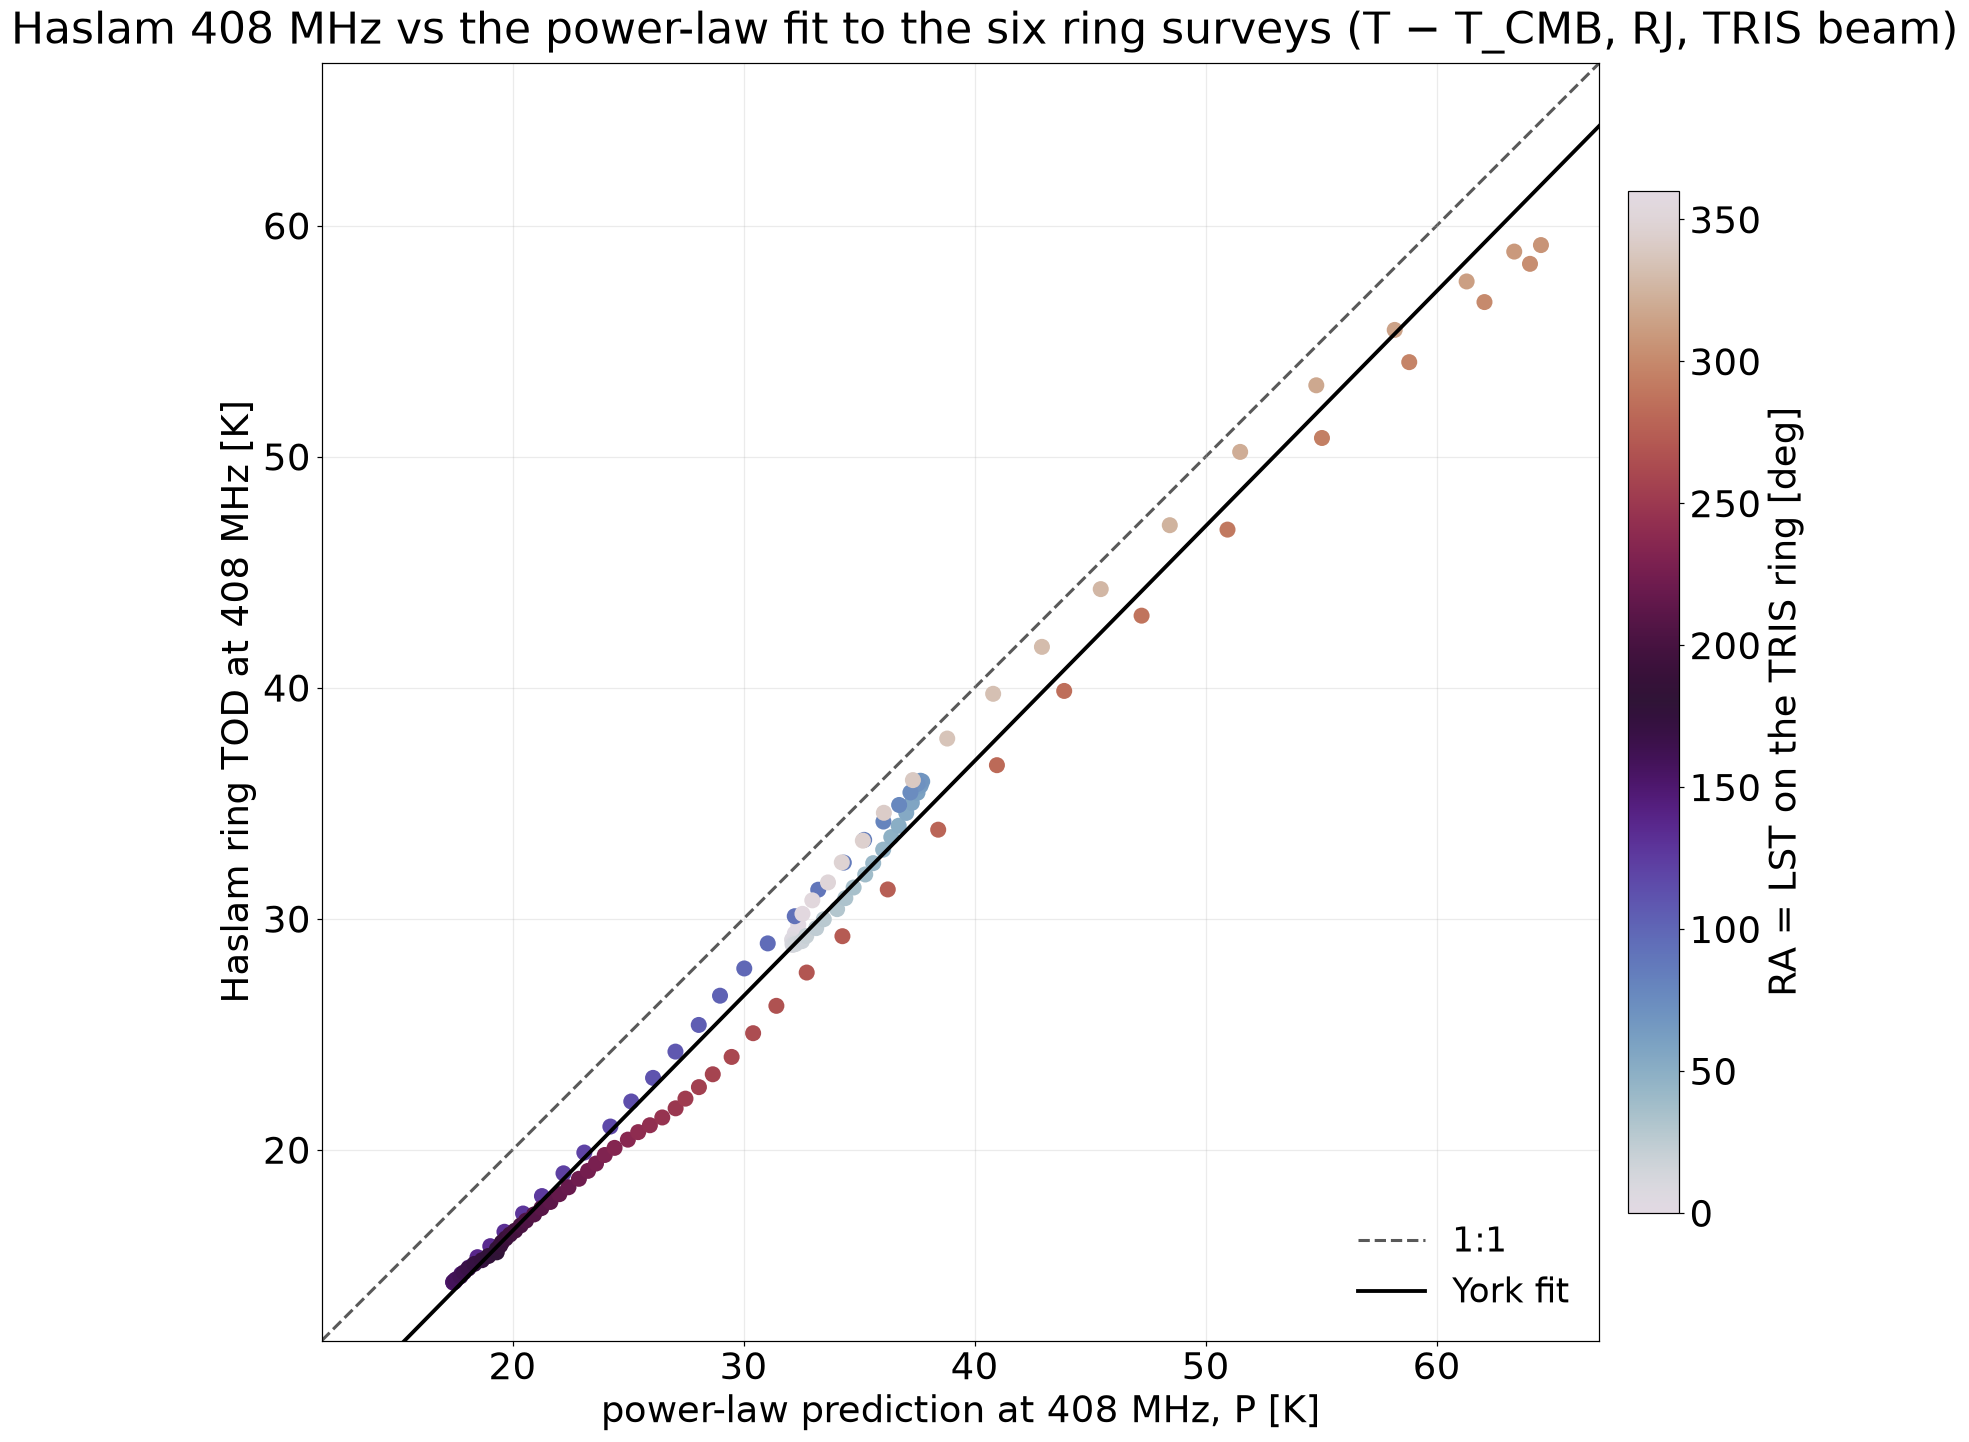

saved model_comparison/plot3_haslam_calibration/fig1_haslam_vs_power_law_tt.png


In [ ]:
fig, ax = plt.subplots(figsize=(15, 13), layout="constrained")
ok = USE
lo = np.nanmin([np.nanmin(P[ok]), np.nanmin(T_H[ok])]); hi = np.nanmax([np.nanmax(P[ok]), np.nanmax(T_H[ok])])
pad = 0.05 * (hi - lo)
lims = np.array([lo - pad, hi + pad])
sc = ax.scatter(P[ok], T_H[ok], c=RA[ok], cmap="twilight", vmin=0, vmax=360, s=110, lw=0, zorder=2)
ax.plot(lims, lims, color="0.35", ls="--", lw=2, label="1:1", zorder=1)
ax.plot(lims, MAIN["g"] * lims + MAIN["z"], color="black", lw=2.5, label="York fit", zorder=3)
ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal")
ax.set_xlabel("power-law prediction at 408 MHz, P [K]")
ax.set_ylabel("Haslam ring TOD at 408 MHz [K]")
ax.grid(alpha=0.25)
ax.legend(frameon=False, loc="lower right")
fig.colorbar(sc, ax=ax, shrink=0.8, pad=0.02, label="RA = LST on the TRIS ring [deg]")
fig.suptitle("Haslam 408 MHz vs the power-law fit to step 5's data sets (T − T_CMB, RJ, TRIS beam)")
save(fig, "fig1_haslam_vs_power_law_tt")

#### Figure 2 — the calibration plane (main result)

The correction to Haslam, $T_\mathrm{corrected} = s\,T_\mathrm{Haslam} + o$. The fitted calibration
(all samples) is the filled green circle with its shaded 1σ ellipse. The ellipse uses the full (s, o)
covariance propagated from York's (g, z) covariance. The open green square with the dashed ellipse is the
same fit with Cygnus A ± 25° excluded. Carter, Irfan and GINAN are each correction's own (s, o) from
Section 3, and the star is uncorrected Haslam, (1, 0). The legend identifies each point. **σ are
underestimates** (correlated samples; common errors treated as independent).

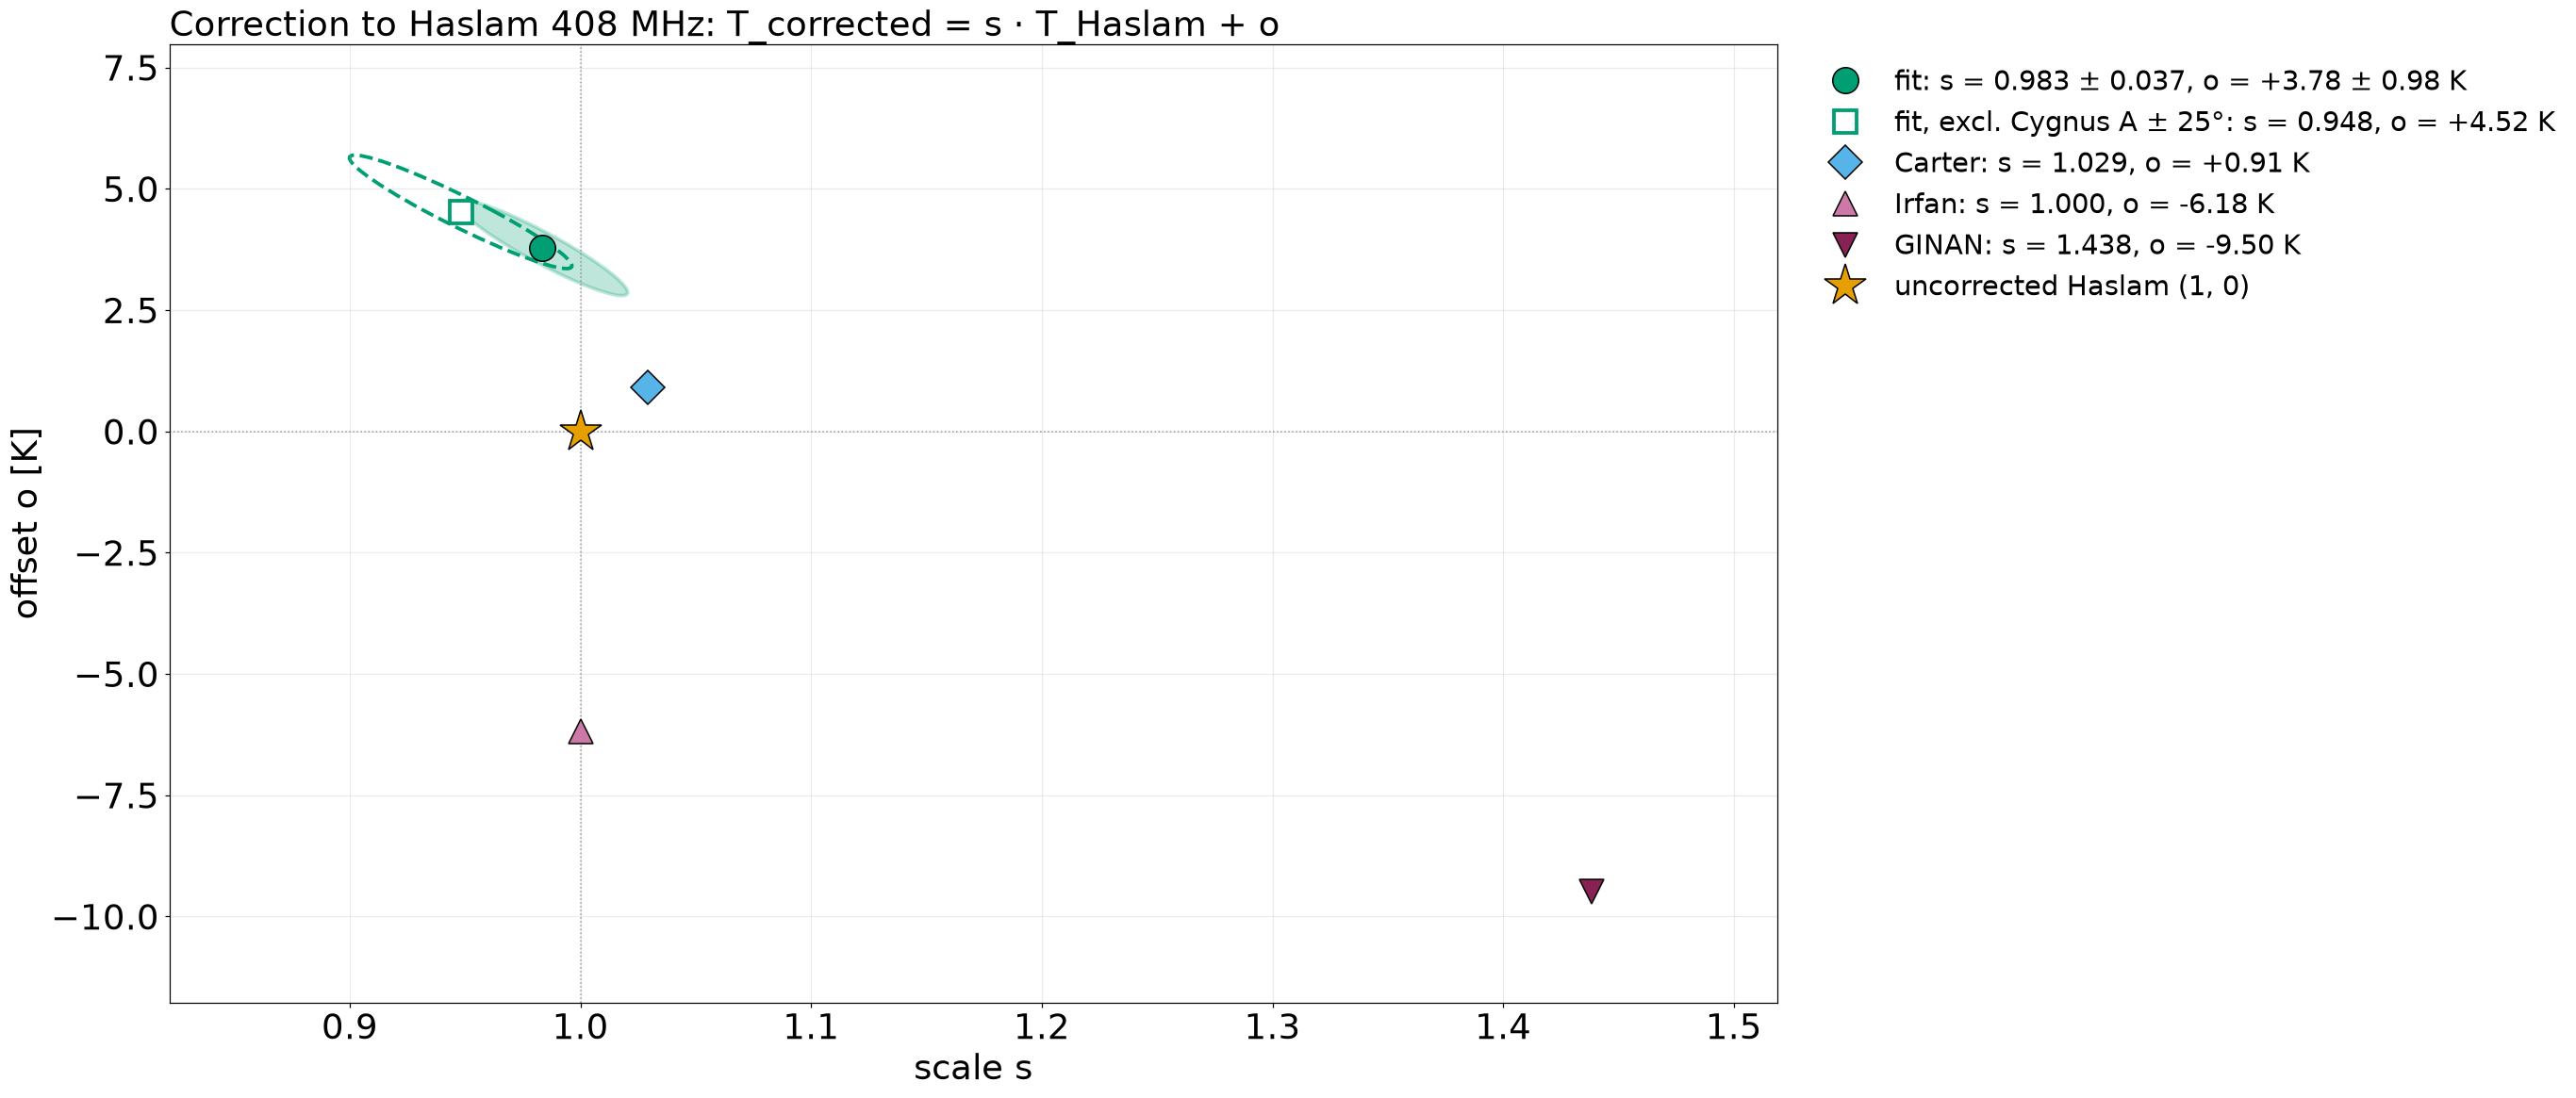

saved model_comparison/plot3_haslam_calibration/fig2_calibration_plane.png


In [ ]:
def ellipse(c, nsig=1.0, **kw):
    w, V = np.linalg.eigh(c["C_so"])
    ang = np.degrees(np.arctan2(V[1, 1], V[0, 1]))
    return Ellipse((c["s"], c["o"]), 2 * nsig * np.sqrt(w[1]), 2 * nsig * np.sqrt(w[0]), angle=ang, **kw)

cx = CAL[True]
fig, ax = plt.subplots(figsize=(20, 12))
ax.add_patch(ellipse(MAIN, fc=COLOUR["fit"], ec=COLOUR["fit"], alpha=0.25, lw=2.5))
ax.add_patch(ellipse(cx, fc="none", ec=COLOUR["fit"], ls="--", lw=2.5))
ax.plot(MAIN["s"], MAIN["o"], "o", ms=18, color=COLOUR["fit"], mec="black", ls="none", zorder=4,
        label=f"fit: s = {MAIN['s']:.3f} ± {MAIN['ss']:.3f}, o = {MAIN['o']:+.2f} ± {MAIN['so']:.2f} K")
ax.plot(cx["s"], cx["o"], "s", ms=16, mfc="white", mec=COLOUR["fit"], mew=2.5, ls="none", zorder=4,
        label=f"fit, excl. Cygnus A ± 25°: s = {cx['s']:.3f}, o = {cx['o']:+.2f} K")
for short, marker in zip(CORR, ("D", "^", "v")):
    c = CORR[short]
    ax.plot(c["s"], c["o"], marker, ms=17, color=COLOUR[short], mec="black", ls="none", zorder=4,
            label=f"{short}: s = {c['s']:.3f}, o = {c['o']:+.2f} K")
ax.plot(1, 0, marker="*", ms=30, color=COLOUR["Haslam"], mec="black", ls="none", zorder=5,
        label="uncorrected Haslam (1, 0)")
ax.axvline(1, color="0.6", lw=1, ls=":"); ax.axhline(0, color="0.6", lw=1, ls=":")
ax.margins(0.15)
ax.set_xlabel("scale s")
ax.set_ylabel("offset o [K]")
ax.grid(alpha=0.25)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=19)
ax.set_title("Correction to Haslam 408 MHz: T_corrected = s · T_Haslam + o", loc="left")
save(fig, "fig2_calibration_plane")

#### Figure 3 — along the ring

**Top:** the power-law prediction P_i (black, with its ±1σ band, about 0.5% wide), uncorrected Haslam,
Haslam with the fitted correction (s, o), and the Carter- and Irfan-corrected Haslam TODs. **Bottom:**
each Haslam version minus P_i, in K, with P's ±1σ band around 0. The light grey shading is RA
299.9 ± 25° (Cygnus A), given in the legend. **σ are underestimates** (correlated samples).

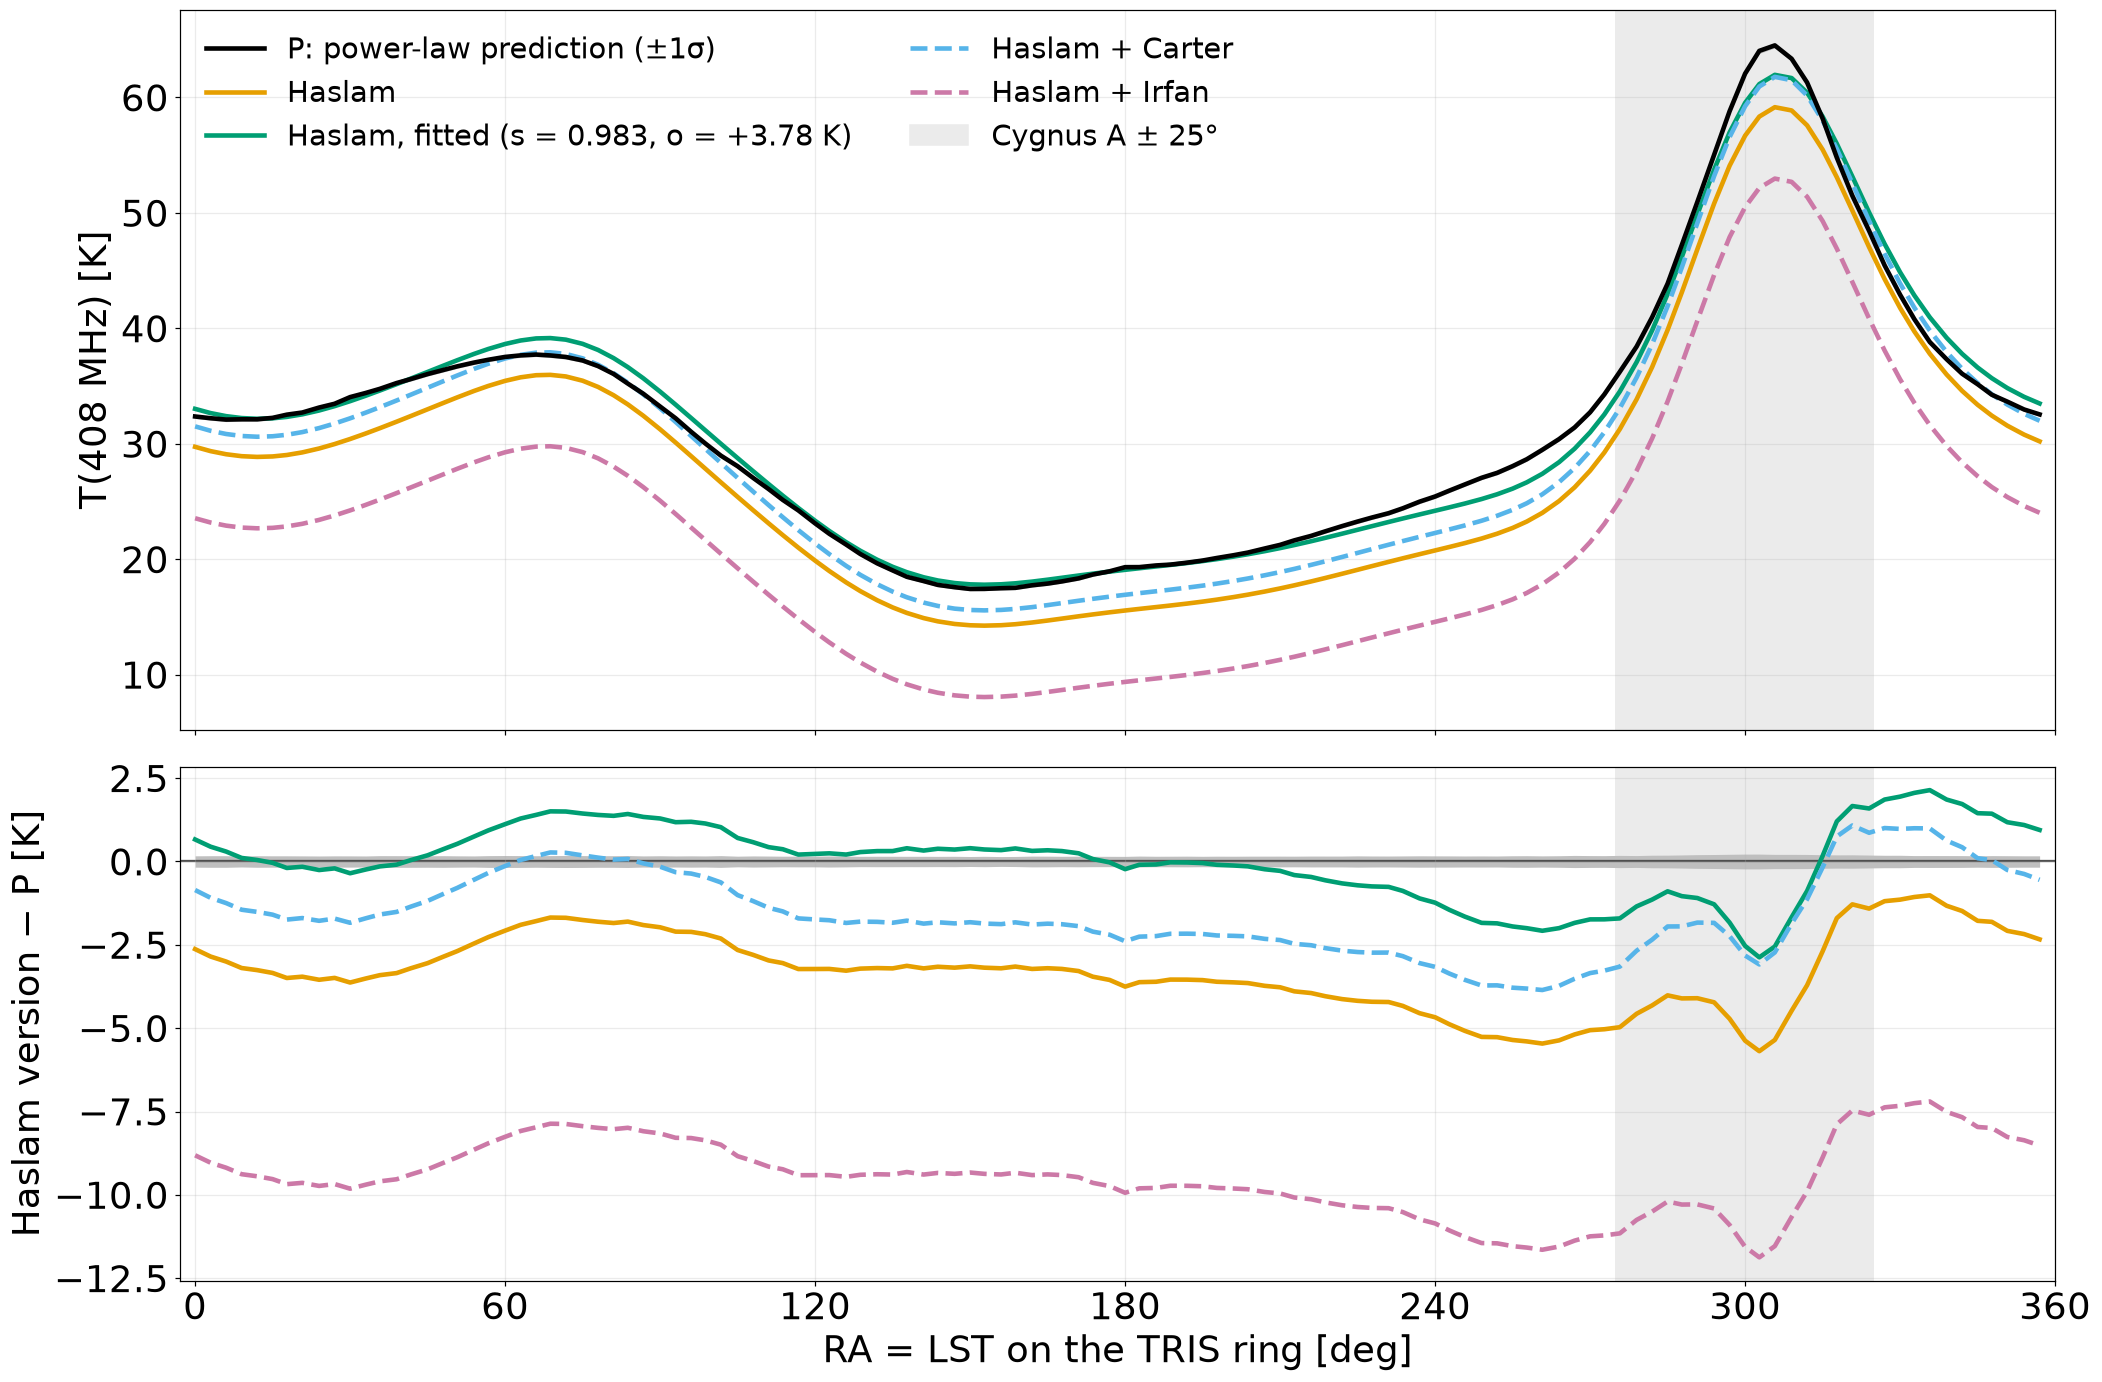

saved model_comparison/plot3_haslam_calibration/fig3_along_ring.png


In [ ]:
H_FIT = MAIN["s"] * T_H + MAIN["o"]
LINES = {"Haslam": (T_H, "-"), f"Haslam, fitted (s = {MAIN['s']:.3f}, o = {MAIN['o']:+.2f} K)": (H_FIT, "-"),
         "Haslam + Carter": (T_MOD["Haslam, Carter correction"], "--"), "Haslam + Irfan": (T_MOD["Haslam, Irfan correction"], "--")}
LCOL = dict(zip(LINES, [COLOUR["Haslam"], COLOUR["fit"], COLOUR["Carter"], COLOUR["Irfan"]]))
Pm = np.where(USE, P, np.nan); Sm = np.where(USE, S_P, np.nan)

fig, (ax, axr) = plt.subplots(2, 1, figsize=(22, 15), sharex=True, gridspec_kw=dict(height_ratios=[1.4, 1], hspace=0.06))
for a in (ax, axr):
    a.axvspan(CYG_A_RA - CYG_HALF, CYG_A_RA + CYG_HALF, color="0.92", lw=0, zorder=0)
ax.fill_between(RA, Pm - Sm, Pm + Sm, color="0.75", lw=0, zorder=1)
ax.plot(RA, Pm, color=COLOUR["P"], lw=3, label="P: power-law prediction (±1σ)", zorder=3)
axr.fill_between(RA, -Sm, Sm, color="0.75", lw=0, zorder=1)
axr.axhline(0, color="0.3", lw=1.5, zorder=1)
for lab, (y, ls) in LINES.items():
    yy = np.where(USE, y, np.nan)
    ax.plot(RA, yy, lw=3, ls=ls, color=LCOL[lab], label=lab, zorder=2)
    axr.plot(RA, yy - Pm, lw=3, ls=ls, color=LCOL[lab], zorder=2)
ax.set_ylabel("T(408 MHz) [K]")
axr.set_ylabel("Haslam version − P [K]")
axr.set_xlabel("RA = LST on the TRIS ring [deg]")
axr.set_xlim(-3, 360); axr.set_xticks(np.arange(0, 361, 60))
for a in (ax, axr):
    a.grid(alpha=0.25)
h, l = ax.get_legend_handles_labels()
h.append(Patch(color="0.92")); l.append("Cygnus A ± 25°")
ax.legend(h, l, frameon=False, ncol=2, loc="upper left", fontsize=19)
save(fig, "fig3_along_ring")

### Table — calibration fits and published corrections

The first two rows are the York gain–offset fits, with all samples and with RA 299.9 ± 25° excluded.
Each gives g, z, χ²/ν, N and the correction (s, σ_s, o, σ_o, and their correlation ρ). The last three
rows are the published corrections' own (s_k, o_k) and the rms scatter about that line. Saved as
`haslam_calibration.csv`. **σ are underestimates** (correlated samples).

In [ ]:
rows = []
for ex, c in CAL.items():
    rows.append({"row": "fit, power-law prediction (step 5)", "samples": "excluding Cygnus A ± 25°" if ex else "all",
                 "s": c["s"], "σ_s": c["ss"], "o [K]": c["o"], "σ_o [K]": c["so"], "ρ(s, o)": c["rho_so"],
                 "g": c["g"], "σ_g": c["sg"], "z [K]": c["z"], "σ_z [K]": c["sz"], "χ²/ν": c["chi2_dof"], "N": c["n"],
                 "scatter [K]": np.nan})
for short, c in CORR.items():
    rows.append({"row": f"published: {short}", "samples": "all (coverage ≥ 0.5)", "s": c["s"], "σ_s": np.nan,
                 "o [K]": c["o"], "σ_o [K]": np.nan, "ρ(s, o)": np.nan, "g": np.nan, "σ_g": np.nan, "z [K]": np.nan,
                 "σ_z [K]": np.nan, "χ²/ν": np.nan, "N": c["n"], "scatter [K]": c["scatter"]})
tab = pd.DataFrame(rows)
tab.to_csv(OUT_DIR / "haslam_calibration.csv", index=False)
print(f"saved {(OUT_DIR / 'haslam_calibration.csv').relative_to(REPO)}  (σ inflated by √(χ²/ν) when > 1: {INFLATE})\n")
with pd.option_context("display.width", 260, "display.max_columns", 30):
    print(tab.round(4).to_string(index=False))

saved model_comparison/plot3_haslam_calibration/haslam_calibration.csv  (σ inflated by √(χ²/ν) when > 1: True)

                                 row                  samples      s    σ_s   o [K]  σ_o [K]  ρ(s, o)      g    σ_g   z [K]  σ_z [K]   χ²/ν   N  scatter [K]
fit, six-survey power-law prediction                      all 0.9834 0.0370  3.7817   0.9846  -0.9306 1.0168 0.0383 -3.8454   1.1371 0.0645 120          NaN
fit, six-survey power-law prediction excluding Cygnus A ± 25° 0.9481 0.0482  4.5238   1.1692  -0.9512 1.0548 0.0536 -4.7717   1.4660 0.0565 103          NaN
                   published: Carter     all (coverage ≥ 0.5) 1.0290    NaN  0.9100      NaN      NaN    NaN    NaN     NaN      NaN    NaN 120       0.0000
                    published: Irfan     all (coverage ≥ 0.5) 1.0000    NaN -6.1843      NaN      NaN    NaN    NaN     NaN      NaN    NaN 120       0.0000
                    published: GINAN     all (coverage ≥ 0.5) 1.4383    NaN -9.4960      NaN      NaN  

### Summary

Results from the run on 2026-10-27: 120 ring samples (103 without Cygnus A ± 25°). Every sample's power-law
fit has all six ring surveys (≥ 4 required). χ²/ν is 0.06 in both fits, so no σ is inflated. **Every σ is
an underestimate** (correlated samples, roughly ×2.6; common errors treated as independent). s and o are
strongly anti-correlated (ρ ≈ −0.93), so the 1σ region is the tilted ellipse in Figure 2, not the two
marginal errors. The distances in σ below use the marginal errors only.

* **Fitted correction: s = 0.980 ± 0.037, o = +3.86 ± 0.98 K.** This is from g = 1.021 ± 0.038 and
  z = −3.94 ± 1.14 K, over N = 120. The scale is 0.6σ from 1; the offset is 3.9σ from 0. Uncorrected
  Haslam − P has a median of −3.2 K. After the fitted correction, Haslam − P is −1.9 to +1.4 K outside
  RA 255–345°, and −2.7 to +2.2 K inside it (Figure 3).
* **Carter's and Irfan's scales lie within 1.4σ of the fitted scale; their offsets do not match it.**
  * Carter: s = 1.029 is 1.3σ above the fitted s; o = +0.91 K is 3.0σ below the fitted o.
  * Irfan: s = 1.000 is 0.6σ above; o = −6.18 K has the opposite sign to the fitted +3.86 K, 10σ away.
  * Both corrections are reproduced exactly by the straight-line fit on uncorrected Haslam (rms
    scatter ~1e-14 K).
* **GINAN is the farthest point:** its best straight line on Haslam is s = 1.426, o = −9.21 K, with an rms
  scatter of 1.25 K about that line. That is 0.45 above the fitted s and 13.1 K below the fitted o.
* **The fit lies between uncorrected Haslam and the published offsets in a specific direction:** it moves
  Haslam up by 3.9 K at a scale just below 1. Carter moves it up by 0.9 K at a scale above 1, and Irfan
  down by 6.2 K at a scale of 1.
* **Excluding Cygnus A ± 25° moves the fit along the ellipse: s = 0.948 ± 0.048, o = +4.52 ± 1.17 K**
  (Δs = −0.032, Δo = +0.67 K, within 1σ).

In [ ]:
# Total notebook run time: from the first code cell (which sets _NB_T0) to here.
import time as _nb_time
if "_NB_T0" in globals():
    _dt = _nb_time.time() - _NB_T0
    print(f"total notebook run time: {_dt:.0f} s ({int(_dt // 3600)}h {int(_dt % 3600 // 60):02d}m {int(_dt % 60):02d}s)")
else:
    print("total notebook run time: not recorded (the first code cell was not run)")